# Modelo de PD de originación – María Isabel Aristizabal Alzate
Objetivo: construir y validar un modelo de probabilidad de incumplimiento
para solicitantes sin historial en buró, usando datos alternativos.

## 1. Carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RAW = Path("../data/raw")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

In [2]:
sol_raw = pd.read_csv(RAW / "dataset_candidato.csv", sep=";", dtype=str, keep_default_na=False)
car_raw = pd.read_csv(RAW / "cartera_variable_respuesta_candidato.csv", dtype=str, keep_default_na=False)
print("Solicitudes:", sol_raw.shape, "| Cartera:", car_raw.shape)

Solicitudes: (4000, 19) | Cartera: (18169, 5)


In [3]:
sol_raw.head()

,application_id,application_date,age,sexo,monthly_income_declared,app_tenure_months,avg_monthly_topups,num_transactions_last_90d,pct_p2p_transfers,device_price_tier,has_bureau_record,bureau_score,utility_payment_ontime_rate,telco_payment_ontime_rate,digital_engagement_score,monto_bono_referidos,requested_amount,product_type,disbursed_flag
0,CAND-02052,1/01/24,22,M,1149897.0,7,14838.0,2,0.712,3,FALSE,,0.524,0.728,52.7,0.0,1160359.0,compra_cartera,TRUE
1,CAND-00752,1/01/24,33,M,616023.0,11,51171.0,3,0.288,3,FALSE,,0.822,0.938,50.3,0.0,273514.0,libre_inversion,TRUE
2,CAND-00542,1/01/24,43,M,3064570.0,7,31961.0,6,0.36,1,FALSE,,0.547,0.915,81.2,0.0,283447.0,libre_inversion,TRUE
3,CAND-01204,1/01/24,34,H,1817355.0,7,43710.0,3,0.515,2,FALSE,,0.501,0.922,59.6,0.0,741165.0,libre_inversion,TRUE
4,CAND-02825,1/01/24,30,M,879261.0,5,37064.0,2,0.544,4,TRUE,530.0,0.697,0.738,19.5,0.0,167681.0,avance_efectivo,TRUE


In [4]:
car_raw.head()

,application_id,fecha_apertura,fecha_corte,altura_mora,saldo_capital
0,CAND-00001,2024-03-20,2024-04-19,0,428989.0
1,CAND-00001,2024-03-20,2024-05-19,0,386445.0
2,CAND-00001,2024-03-20,2024-06-18,0,347446.0
3,CAND-00001,2024-03-20,2024-07-18,0,314018.0
4,CAND-00002,2024-08-22,2024-09-21,0,784934.0


En la siguiente celda se revisa, para cada variable que debería ser numérica:
- cuántos valores **no se pueden convertir a número** (indicador de datos corruptos), y
- cuántos valores **nulos** tiene.  
Primero se reemplazan los textos vacíos por nulos reales (`NaN`).

In [5]:
sol = sol_raw.replace("", np.nan)
num_cols = ["age","monthly_income_declared","app_tenure_months","avg_monthly_topups",
            "num_transactions_last_90d","pct_p2p_transfers","device_price_tier","bureau_score",
            "utility_payment_ontime_rate","telco_payment_ontime_rate","digital_engagement_score",
            "monto_bono_referidos","requested_amount"]
pd.DataFrame({
    "no_numericos": {c: int((pd.to_numeric(sol[c], errors="coerce").isna() & sol[c].notna()).sum()) for c in num_cols},
    "nulos": sol[num_cols].isna().sum(),
})

,no_numericos,nulos
age,0,0
monthly_income_declared,49,0
app_tenure_months,0,0
avg_monthly_topups,0,0
num_transactions_last_90d,0,0
pct_p2p_transfers,0,0
device_price_tier,0,0
bureau_score,0,2191
utility_payment_ontime_rate,0,255
telco_payment_ontime_rate,0,241


En la siguiente celda se verifica que `application_id` sea una llave única
y se revisan las frecuencias de las variables categóricas y binarias
para detectar niveles inesperados.

In [6]:
print("IDs duplicados:", sol["application_id"].duplicated().sum())
for c in ["sexo", "product_type", "has_bureau_record", "disbursed_flag", "device_price_tier"]:
    print(c, sol[c].value_counts(dropna=False).to_dict())

IDs duplicados: 0
sexo {'H': 1984, 'M': 1853, 'NB': 163}
product_type {'libre_inversion': 2192, 'avance_efectivo': 1004, 'compra_cartera': 804}
has_bureau_record {'FALSE': 2191, 'TRUE': 1809}
disbursed_flag {'TRUE': 3930, 'FALSE': 70}
device_price_tier {'1': 1236, '2': 1087, '3': 848, '4': 554, '5': 275}


En la siguiente celda vemos los registros de `monthly_income_declared` que no se pudieron convertir a número, para entender por qué paso esto.

In [7]:
sol.loc[pd.to_numeric(sol["monthly_income_declared"], errors="coerce").isna(),
        ["application_id", "monthly_income_declared"]].head(10)

,application_id,monthly_income_declared
163,CAND-02580,13.760.566.878.899.200
178,CAND-00518,13.777.722.536.049.300
243,CAND-01908,7.071.149.473.249.980
296,CAND-02728,14.990.568.150.977.100
316,CAND-00750,24.123.345.785.788.900
469,CAND-01013,1.924.125.405.490.580
706,CAND-00506,2.686.018.256.156.650
744,CAND-00272,10.393.513.001.866.500
859,CAND-01997,961.705.411.118.913
930,CAND-02771,9.475.369.019.294.410


### Hallazgos de la carga inicial

- **Formato de archivos:** el dataset de solicitudes viene separado por `;` y el de cartera
  por `,`. Se leyeron ambos como texto (`dtype=str`) para no imponer tipos y poder
  detectar anomalías de formato antes de convertir.
- **Tamaño:** 4.000 solicitudes (19 variables) y 18.169 registros de cartera
  (panel mensual: varios cortes por crédito).
- **Llave:** `application_id` es única en solicitudes (0 duplicados).
- **Ingreso con formato corrupto:** 49 registros de `monthly_income_declared` (1,2 %) no
  son numéricos, p. ej. `13.760.566.878.899.200`. Parece un número decimal exportado con
  separadores de miles locales donde se perdió la coma decimal
  (≈ 1.376.056,68). No se eliminan: en el siguiente paso se intenta recuperarlos.
- **Nulos:**
  - `bureau_score` tiene 2.191 nulos, exactamente el mismo número de solicitudes con
    `has_bureau_record = FALSE` → es un **nulo estructural** (clientes thin-file),
    no un dato faltante.
  - `utility_payment_ontime_rate` (255) y `telco_payment_ontime_rate` (241) tienen
    ~6 % de nulos → faltantes reales de datos alternativos.
- **Desembolso:** 70 solicitudes (1,75 %) no se desembolsaron; no deberían tener
  registro en cartera ni desempeño observable.
- **Categóricas:** `sexo` (H 1.984, M 1.853, NB 163), `product_type` con 3 niveles,
  `device_price_tier` de 1 a 5. Sin categorías inesperadas.

## 2. Calidad de datos – solicitudes

### 2.1 Recuperar el ingreso corrupto.
En la siguiente celda vemos los ingresos con formato corrupto.  

**Regla**: se eliminarán los puntos y se toma el prefijo de dígitos cuyo valor cae dentro del rango de ingresos válidos observados (mínimo y máximo de los registros normales).
Si existe exactamente un candidato, se usa; si hay ambigüedad, se deja nulo.
Se crea `flag_income_recovered` para trazabilidad, y se compara la distribución
de los ingresos recuperados contra la de los válidos para confirmar que la regla
produce valores coherentes.

In [8]:
ok_inc = pd.to_numeric(sol["monthly_income_declared"], errors="coerce")
INC_MIN, INC_MAX = ok_inc.min(), ok_inc.max() * 1.01
print(f"Rango de ingresos válidos: {INC_MIN:,.0f} – {ok_inc.max():,.0f}")

def recuperar_ingreso(valor):
    v = pd.to_numeric(valor, errors="coerce")
    if pd.notna(v):
        return v, 0
    digitos = str(valor).replace(".", "")
    candidatos = [int(digitos[:L]) for L in range(4, len(digitos))
                  if INC_MIN <= int(digitos[:L]) <= INC_MAX]
    return (float(candidatos[0]), 1) if len(candidatos) == 1 else (np.nan, 1)

tmp = sol["monthly_income_declared"].map(recuperar_ingreso)
sol["income"] = tmp.map(lambda t: t[0])
sol["flag_income_recovered"] = tmp.map(lambda t: t[1])

rec = sol[sol.flag_income_recovered == 1]
print("Recuperados:", rec["income"].notna().sum(), "de", len(rec))
display(rec[["monthly_income_declared", "income"]].head())
pd.concat([ok_inc.describe().rename("validos"), rec["income"].describe().rename("recuperados")], axis=1)

Rango de ingresos válidos: 300,000 – 5,067,733
Recuperados: 49 de 49


,monthly_income_declared,income
163,13.760.566.878.899.200,1376056.0
178,13.777.722.536.049.300,1377772.0
243,7.071.149.473.249.980,707114.0
296,14.990.568.150.977.100,1499056.0
316,24.123.345.785.788.900,2412334.0


,validos,recuperados
count,3.951000e+03,4.900000e+01
mean,1.333014e+06,1.395187e+06
std,6.270366e+05,5.967551e+05
min,3.000000e+05,5.208970e+05
25%,8.899220e+05,9.617050e+05
50%,1.201639e+06,1.218382e+06
75%,1.624324e+06,1.718219e+06
max,5.067733e+06,2.924354e+06


### 2.2 Convertir tipos y fechas
En la siguiente celda se convierten las variables a su tipo correcto: numéricas a número, banderas `TRUE/FALSE` a booleano y `application_date` a fecha con formato  `d/mm/yy`. Se verifica que no queden fechas sin convertir y se revisa el número de solicitudes por mes.

In [9]:
for c in num_cols:
    if c != "monthly_income_declared":
        sol[c] = pd.to_numeric(sol[c])
for c in ["has_bureau_record", "disbursed_flag"]:
    sol[c] = sol[c].astype(str).str.upper().eq("TRUE")   # funciona sea texto o booleano

if sol["application_date"].dtype == object or str(sol["application_date"].dtype).startswith("str"):
    print("Longitudes de application_date:", sol["application_date"].str.len().value_counts().to_dict())
    sol["application_date"] = pd.to_datetime(sol["application_date"], format="%d/%m/%y", errors="coerce")
print("Fechas no parseables:", sol["application_date"].isna().sum(),
      "| rango:", sol["application_date"].min().date(), "→", sol["application_date"].max().date())
print(sol[["has_bureau_record", "disbursed_flag"]].value_counts().to_dict())
sol["application_date"].dt.to_period("M").value_counts().sort_index()

Longitudes de application_date: {8: 2857, 7: 1143}
Fechas no parseables: 0 | rango: 2024-01-01 → 2024-12-31
{(False, True): 2152, (True, True): 1778, (False, False): 39, (True, False): 31}


application_date
2024-01    343
2024-02    339
2024-03    335
2024-04    352
2024-05    333
2024-06    359
2024-07    302
2024-08    337
2024-09    300
2024-10    346
2024-11    324
2024-12    330
Freq: M, Name: count, dtype: int64

### 2.3 Reglas de consistencia de negocio
En la siguiente celda se validan reglas de consistencia de negocio:
- que el score de buró sea nulo sólo cuando no hay registro en buró,
- que esté en un rango válido,
- que las tasas estén entre 0 y 1,
- que los scores y niveles estén en su escala,
- que la edad sea de un adulto
- y que montos y conteos no sean negativos.

In [10]:
reglas = {
    "bureau_score nulo ⇔ sin buró": ((sol.bureau_score.isna()) == (~sol.has_bureau_record)).all(),
    "bureau_score en [300, 900]": sol.bureau_score.dropna().between(300, 900).all(),
    "tasas en [0, 1]": all(sol[c].dropna().between(0, 1).all() for c in
                          ["utility_payment_ontime_rate", "telco_payment_ontime_rate", "pct_p2p_transfers"]),
    "engagement en [0, 100]": sol.digital_engagement_score.between(0, 100).all(),
    "device_price_tier en 1..5": sol.device_price_tier.isin(range(1, 6)).all(),
    "edad en [18, 100]": sol.age.between(18, 100).all(),
    "montos y conteos ≥ 0": (sol[["avg_monthly_topups", "num_transactions_last_90d", "monto_bono_referidos",
                                  "requested_amount", "app_tenure_months"]] >= 0).all().all(),
}
pd.Series(reglas, name="cumple").to_frame()

,cumple
bureau_score nulo ⇔ sin buró,True
"bureau_score en [300, 900]",True
"tasas en [0, 1]",True
"engagement en [0, 100]",True
device_price_tier en 1..5,True
"edad en [18, 100]",True
montos y conteos ≥ 0,True


### Hallazgos – calidad de datos de solicitudes

- **Ingresos recuperados:** los 49 ingresos corruptos se recuperaron sin ambigüedad
  (un único candidato en el rango válido de 300.000 – 5.067.733). La distribución de
  los recuperados (mediana ≈ 1,22 M) es muy similar a la de los válidos
  (mediana ≈ 1,20 M), lo que respalda la regla. Se conserva `flag_income_recovered`
  para trazabilidad.
- **Fechas de solicitud:** todas se convirtieron (0 errores). Van del 01-01-2024 al
  31-12-2024, con un volumen estable de ≈ 300–360 solicitudes por mes, sin meses
  faltantes ni picos atípicos.
- **Reglas de negocio:** se cumplen todas. En particular, `bureau_score` es nulo
  **si y sólo si** el cliente no tiene registro en buró, confirmando que es un nulo
  estructural y no un dato faltante que deba imputarse.
- **Nota de reproducibilidad:** la conversión de tipos se escribió de forma que
  pueda re-ejecutarse sin alterar los datos (idempotente).

### 2.4 Atípicos y anomalías de distribución
En la siguiente celda se construye un resumen estadístico de las variables numéricas
con percentiles extremos (1 %, 5 %, 95 %, 99 %). Además se calcula, para cada variable,
el porcentaje de valores atípicos según el criterio de 3 rangos intercuartílicos
(más conservador que el 1,5·IQR clásico, para marcar sólo extremos reales) y la
asimetría (*skew*) para identificar distribuciones con colas largas.

In [11]:
vars_num = ["age", "income", "app_tenure_months", "avg_monthly_topups", "num_transactions_last_90d",
            "pct_p2p_transfers", "bureau_score", "utility_payment_ontime_rate", "telco_payment_ontime_rate",
            "digital_engagement_score", "monto_bono_referidos", "requested_amount"]

desc = sol[vars_num].describe(percentiles=[.01, .05, .5, .95, .99]).T
atipicos = {}
for c in vars_num:
    s = sol[c].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    atipicos[c] = ((s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)).mean()
desc["pct_atipicos_3IQR"] = pd.Series(atipicos)
desc["skew"] = sol[vars_num].skew()
desc.round(3)

,count,mean,std,min,1%,5%,50%,95%,99%,max,pct_atipicos_3IQR,skew
age,4000.0,34.834,9.668,18.000,18.000,18.000,35.000,51.000,58.000,65.000,0.000,0.192
income,4000.0,1333775.318,626640.661,300000.000,436530.500,568595.050,1202313.000,2537853.350,3424989.750,5067733.000,0.005,1.368
app_tenure_months,4000.0,13.546,12.765,1.000,1.000,1.000,10.000,40.000,60.000,60.000,0.000,1.499
avg_monthly_topups,4000.0,49658.367,35505.372,818.000,3843.670,9354.500,41322.500,118011.900,169245.000,321154.000,0.005,1.558
num_transactions_last_90d,4000.0,6.828,6.892,0.000,0.000,0.000,5.000,21.000,30.010,49.000,0.004,1.618
pct_p2p_transfers,4000.0,0.397,0.199,0.006,0.041,0.097,0.384,0.750,0.852,0.969,0.000,0.306
bureau_score,1809.0,652.796,83.521,386.000,453.160,512.400,652.000,790.600,845.000,900.000,0.000,-0.029
utility_payment_ontime_rate,3745.0,0.730,0.148,0.165,0.332,0.456,0.750,0.935,0.970,0.998,0.000,-0.640
telco_payment_ontime_rate,3759.0,0.731,0.147,0.144,0.339,0.466,0.751,0.933,0.970,0.999,0.000,-0.644
digital_engagement_score,4000.0,50.246,19.615,0.000,3.197,17.700,50.250,83.000,96.600,100.000,0.000,-0.005


En la siguiente celda se grafica el histograma de cada variable numérica para
revisar visualmente la forma de las distribuciones, concentraciones anómalas
de valores y colas largas.

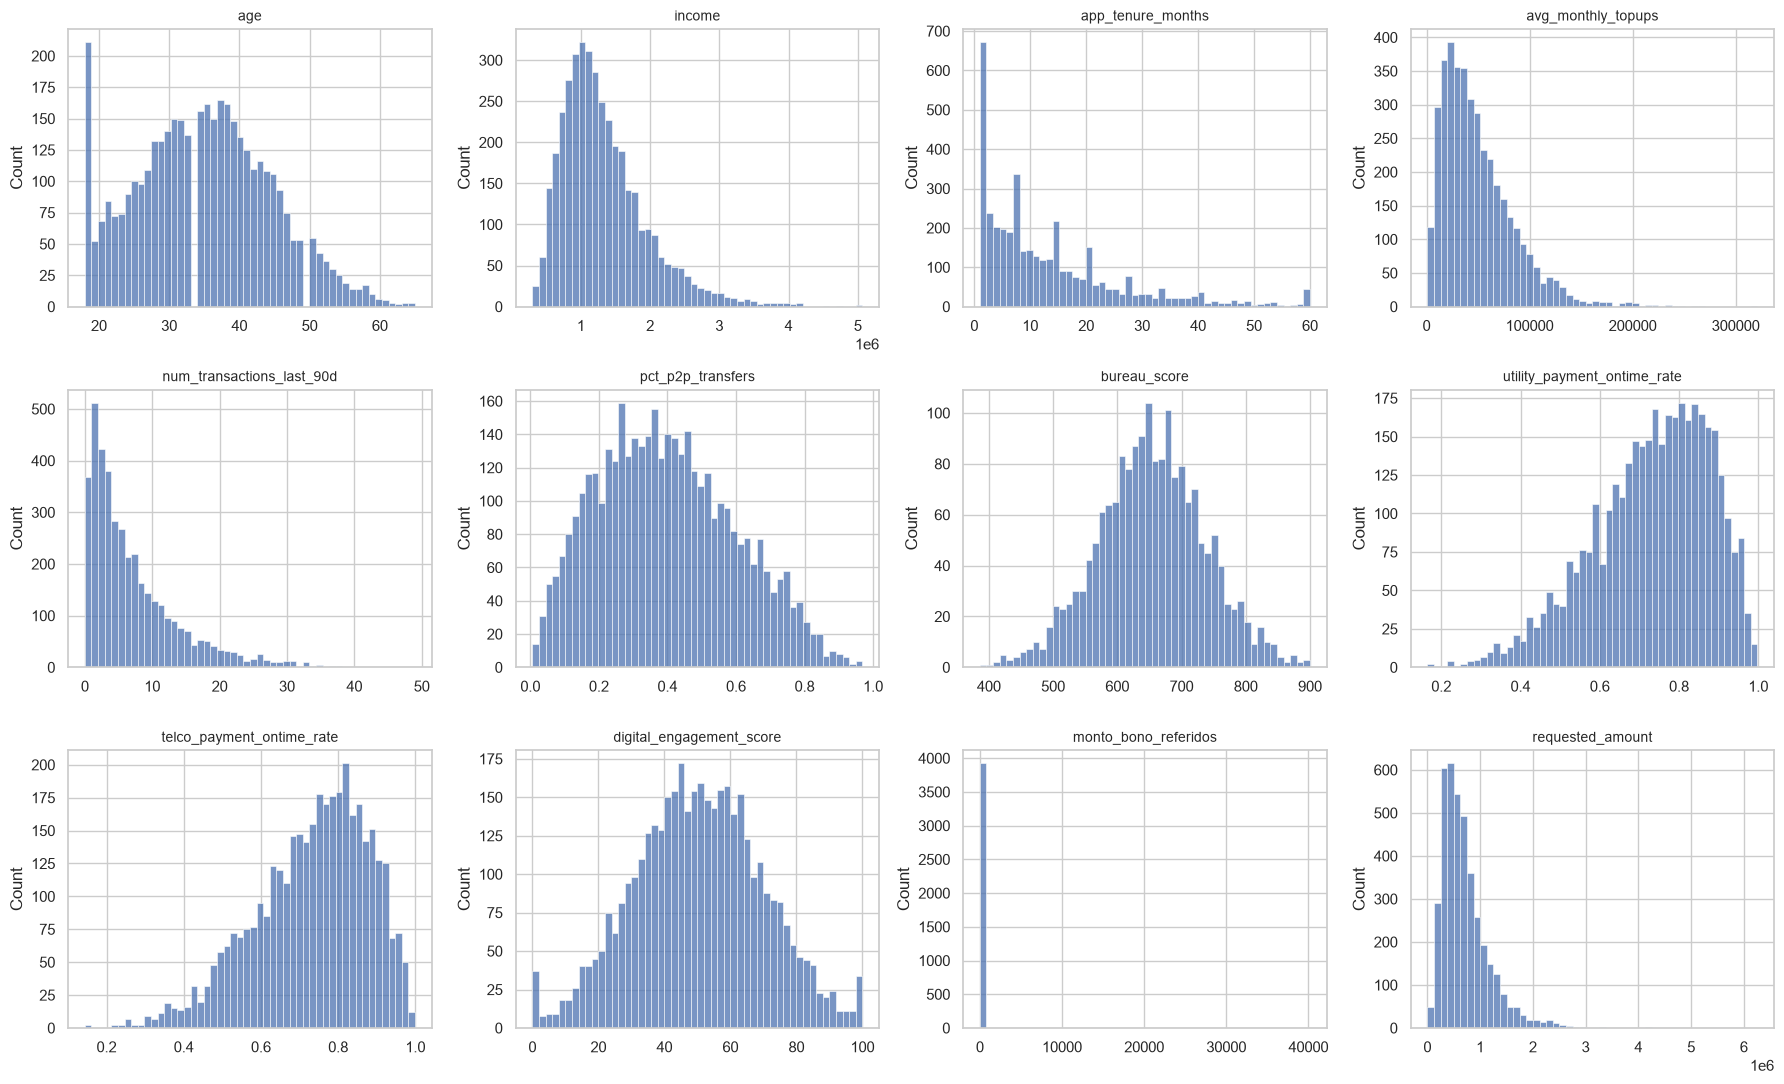

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), vars_num):
    sns.histplot(sol[c].dropna(), bins=50, ax=ax, color="#4C72B0")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

En la siguiente celda se analiza en detalle la distribución de la edad, para verificar
si la acumulación observada en 18 años es natural o anómala comparándola con la
frecuencia de las edades vecinas (19 a 22 años).

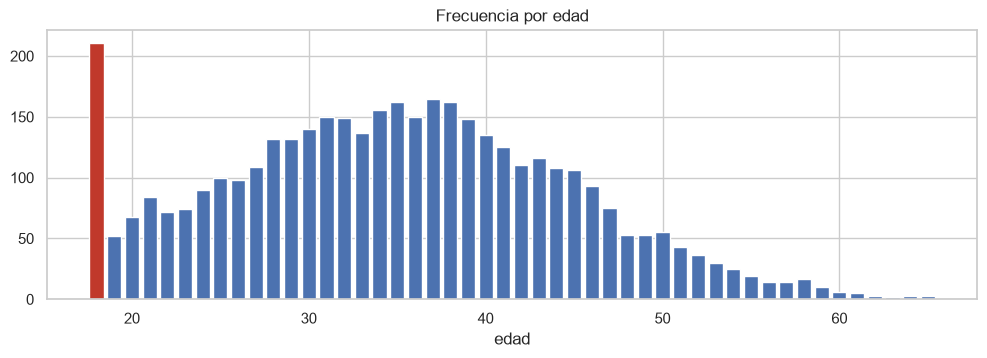

n(edad = 18): 211 | promedio edades 19–22: 69.0


In [13]:
conteo_edad = sol["age"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(conteo_edad.index, conteo_edad.values,
       color=["#C0392B" if a == 18 else "#4C72B0" for a in conteo_edad.index])
ax.set_title("Frecuencia por edad")
ax.set_xlabel("edad")
plt.show()
print("n(edad = 18):", conteo_edad[18], "| promedio edades 19–22:", round(conteo_edad.loc[19:22].mean(), 1))

En la siguiente celda se revisan los montos solicitados más pequeños, ya que el mínimo
(≈ 500) está muy por debajo del percentil 1 (≈ 107.000). Se busca identificar si se trata
de un grupo separado del resto de la distribución (posible error de unidades).

In [14]:
print("Solicitudes con monto < 5.000:", (sol["requested_amount"] < 5000).sum())
print("Solicitudes con monto entre 5.000 y 100.000:", sol["requested_amount"].between(5000, 100000).sum())
sol.nsmallest(30, "requested_amount")[["application_id", "requested_amount", "product_type", "income"]]

Solicitudes con monto < 5.000: 24
Solicitudes con monto entre 5.000 y 100.000: 12


,application_id,requested_amount,product_type,income
3425,CAND-03606,518.0,avance_efectivo,559211.0
2613,CAND-02466,543.0,avance_efectivo,703496.0
2748,CAND-00953,638.0,libre_inversion,2059785.0
3917,CAND-03006,639.0,compra_cartera,1646239.0
1480,CAND-02813,663.0,compra_cartera,627877.0
821,CAND-01049,678.0,compra_cartera,2268891.0
1888,CAND-01867,760.0,compra_cartera,707949.0
3272,CAND-03742,810.0,avance_efectivo,1093383.0
2677,CAND-00853,829.0,avance_efectivo,1569160.0
2271,CAND-00476,899.0,compra_cartera,2286058.0


En la siguiente celda se revisa `monto_bono_referidos`: proporción de ceros y
distribución de los valores positivos, para evaluar si la variable tiene variabilidad
suficiente para ser útil.

In [15]:
print(f"% de ceros: {(sol['monto_bono_referidos'] == 0).mean():.1%}")
sol.loc[sol["monto_bono_referidos"] > 0, "monto_bono_referidos"].describe()

% de ceros: 98.0%


count       78.000000
mean     16680.743590
std       8248.501462
min       5297.000000
25%      10816.250000
50%      15174.500000
75%      19746.250000
max      40189.000000
Name: monto_bono_referidos, dtype: float64

### Hallazgos – atípicos y distribuciones

- **Valores atípicos (3·IQR):** son escasos (< 1 % en todas las variables, salvo
  `monto_bono_referidos`). Las variables de monto y actividad (`income`,
  `avg_monthly_topups`, `num_transactions_last_90d`, `requested_amount`) tienen
  asimetría positiva (colas largas a la derecha), propia de variables monetarias.
  **No se eliminan ni recortan**: el modelo usará binning (WoE), que agrupa los
  extremos en el último rango y es robusto a colas.
- **Edad = 18 anómala:** 211 solicitantes tienen exactamente 18 años, más de 3 veces
  el promedio de las edades 19–22 (69). Es un patrón típico de *clipping* (edades
  menores o inválidas truncadas a 18) o de valor por defecto en el formulario.
  Se marcará con un indicador (`flag_age_18`).
- **Antigüedad en la app:** acumulación en 1 mes (clientes nuevos) y un pico en
  60 meses, que sugiere un **tope** de la variable (antigüedades mayores registradas
  como 60).
- **Engagement digital:** masas en 0 y en 100, extremos de la escala → valores
  truncados a los límites del score.
- **Montos solicitados en miles:** 24 solicitudes tienen montos entre 518 y 1.984,
  separadas del resto por un salto grande (el siguiente valor es 100.000, el
  mínimo del producto). Hipótesis: **capturados en miles**. Se valida en la
  sección de cartera contra el saldo de capital del primer corte.
- **`monto_bono_referidos`:** 98 % de ceros (sólo 78 casos con bono, entre 5 y 40 mil).
  Variable casi constante; se evaluará su poder predictivo, pero probablemente
  no aporte.
- **Datos alternativos** (utility y telco): asimetría negativa, la mayoría paga a
  tiempo; sin atípicos.

## 3. Calidad de datos – cartera

### 3.1 Formatos de fecha
En la siguiente celda se revisa el formato de las fechas del panel de cartera.
Se cuenta cuántas `fecha_apertura` vienen en formato `YYYY-MM-DD` y cuántas en otro
formato, y luego se convierte cada grupo con su patrón explícito: si se usara
inferencia automática, una fecha `DD-MM-YYYY` con día ≤ 12 podría interpretarse
como mes en silencio.

In [16]:
car = car_raw.copy()
iso = car["fecha_apertura"].str.match(r"^\d{4}-\d{2}-\d{2}$")
dmy = car["fecha_apertura"].str.match(r"^\d{2}-\d{2}-\d{4}$")
print(f"fecha_apertura → YYYY-MM-DD: {iso.sum():,} | DD-MM-YYYY: {dmy.sum():,} | otros: {(~iso & ~dmy).sum()}")
print("fecha_corte toda en YYYY-MM-DD:", car["fecha_corte"].str.match(r"^\d{4}-\d{2}-\d{2}$").all())

car["fecha_apertura"] = pd.to_datetime(car["fecha_apertura"].where(iso), format="%Y-%m-%d").fillna(
                        pd.to_datetime(car["fecha_apertura"].where(dmy), format="%d-%m-%Y"))
car["fecha_corte"] = pd.to_datetime(car["fecha_corte"], format="%Y-%m-%d")
car["altura_mora"] = car["altura_mora"].astype(int)
car["saldo_capital"] = car["saldo_capital"].astype(float)

print("Nulos tras convertir:", car[["fecha_apertura", "fecha_corte"]].isna().sum().to_dict())
print("Una sola fecha de apertura por crédito:", (car.groupby("application_id")["fecha_apertura"].nunique() == 1).all())
print("Apertura:", car.fecha_apertura.min().date(), "→", car.fecha_apertura.max().date(),
      "| Corte:", car.fecha_corte.min().date(), "→", car.fecha_corte.max().date())

fecha_apertura → YYYY-MM-DD: 18,087 | DD-MM-YYYY: 82 | otros: 0
fecha_corte toda en YYYY-MM-DD: True
Nulos tras convertir: {'fecha_apertura': 0, 'fecha_corte': 0}
Una sola fecha de apertura por crédito: True
Apertura: 2024-01-04 → 2025-01-29 | Corte: 2024-02-03 → 2025-07-26


### 3.2 Integridad referencial entre datasets
En la siguiente celda se valida la integridad referencial entre los dos datasets:
créditos de cartera sin solicitud, solicitudes no desembolsadas que sí tengan cartera
(no debería ocurrir) y solicitudes desembolsadas sin cartera.

In [17]:
ids_sol, ids_car = set(sol.application_id), set(car.application_id)
no_desemb = set(sol.loc[~sol.disbursed_flag, "application_id"])
desemb = set(sol.loc[sol.disbursed_flag, "application_id"])
huerfanos = sorted(ids_car - ids_sol)

display(pd.Series({
    "IDs únicos en cartera": len(ids_car),
    "En cartera sin solicitud (huérfanos)": len(huerfanos),
    "No desembolsadas con cartera": len(no_desemb & ids_car),
    "Desembolsadas sin cartera": len(desemb - ids_car),
}).to_frame("n"))
print("Ejemplos de huérfanos:", huerfanos[:5])

,n
IDs únicos en cartera,4052
En cartera sin solicitud (huérfanos),122
No desembolsadas con cartera,0
Desembolsadas sin cartera,0


Ejemplos de huérfanos: ['CAND-PH0001', 'CAND-PH0002', 'CAND-PH0003', 'CAND-PH0004', 'CAND-PH0005']


### 3.3 Estructura del panel: cortes, MOB y consistencia temporal
En la siguiente celda se revisa la estructura del panel: se ordena cada crédito por fecha
de corte y se numera cada corte (MOB, *month on book*). Se verifica que no haya cortes
duplicados ni anteriores a la apertura, cuántos días hay entre apertura y cada corte,
cuántos cortes tiene cada crédito, si el saldo aumenta en algún momento (no esperado
en un crédito que amortiza) y cuántos días pasan entre la solicitud y el desembolso.

In [18]:
car = car.sort_values(["application_id", "fecha_corte"]).reset_index(drop=True)
car["mob"] = car.groupby("application_id").cumcount() + 1
car["dias_desde_apertura"] = (car.fecha_corte - car.fecha_apertura).dt.days

print("Duplicados (id, corte):", car.duplicated(["application_id", "fecha_corte"]).sum())
print("Cortes en o antes de la apertura:", (car.fecha_corte <= car.fecha_apertura).sum())
display(car.groupby("mob")["dias_desde_apertura"].agg(["count", "min", "max"]).T)
print("Cortes por crédito:", car.groupby("application_id")["mob"].max().value_counts().sort_index().to_dict())
print("Cortes con aumento de saldo:", (car.groupby("application_id")["saldo_capital"].diff() > 0).sum())

lag = sol.merge(car.groupby("application_id").fecha_apertura.first().reset_index(), on="application_id")
lag["dias"] = (lag.fecha_apertura - lag.application_date).dt.days
print("Días solicitud → desembolso:", lag.dias.describe()[["min", "50%", "max"]].to_dict(),
      "| desembolso antes de solicitud:", (lag.dias < 0).sum())

Duplicados (id, corte): 0
Cortes en o antes de la apertura: 0


mob,1,2,3,4,5,6
count,4052,4052,4052,3031,2000,982
min,30,60,90,120,150,180
max,30,60,90,120,150,180


Cortes por crédito: {3: 1021, 4: 1031, 5: 1018, 6: 982}
Cortes con aumento de saldo: 0
Días solicitud → desembolso: {'min': 0.0, '50%': 15.0, 'max': 30.0} | desembolso antes de solicitud: 0


### 3.4 Número de cortes por cosecha
En la siguiente celda se cruza el mes de apertura (cosecha) con el número de cortes de
cada crédito, para entender si los créditos con menos cortes son simplemente los más
recientes (menos tiempo de observación) o si la cantidad de cortes no depende de la fecha.

In [19]:
resumen = car.groupby("application_id").agg(fecha_apertura=("fecha_apertura", "first"),
                                            n_cortes=("mob", "max"))
resumen["cosecha"] = resumen.fecha_apertura.dt.to_period("M")
pd.crosstab(resumen.cosecha, resumen.n_cortes, margins=True)

n_cortes,3,4,5,6,All
cosecha,,,,,
2024-01,48,50,33,51,182
2024-02,82,73,89,83,327
2024-03,77,85,95,85,342
2024-04,91,82,80,76,329
2024-05,79,103,95,106,383
2024-06,87,78,87,80,332
2024-07,83,86,87,90,346
2024-08,97,92,73,74,336
2024-09,83,80,81,76,320


### 3.5 Escala de `altura_mora`
En la siguiente celda se revisa la escala de `altura_mora`: sus valores posibles,
cómo se distribuyen por MOB y qué tamaño tienen los saltos entre cortes consecutivos
de un mismo crédito.

In [20]:
display(car["altura_mora"].value_counts().sort_index().to_frame("n").T)
display(pd.crosstab(car["mob"], car["altura_mora"].clip(upper=91).replace({91: "91-120"})))
saltos = car.groupby("application_id")["altura_mora"].diff()
print("Saltos de mora entre cortes:", saltos.value_counts().sort_index().to_dict())

altura_mora,0,30,60,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120
n,15001,1687,686,463,9,10,8,12,3,8,15,14,12,10,5,13,8,14,17,19,8,4,12,11,10,13,11,14,3,9,14,13,19,14


altura_mora,0,30,60,90,91-120
mob,,,,,
1,3607,445,0,0,0
2,3413,397,242,0,0
3,3264,397,184,207,0
4,2394,249,157,119,112
5,1568,136,67,103,126
6,755,63,36,34,94


Saltos de mora entre cortes: {-30.0: 789, -29.0: 1, -23.0: 1, -20.0: 1, -8.0: 1, -7.0: 1, -3.0: 1, 0.0: 10836, 1.0: 7, 2.0: 7, 3.0: 7, 4.0: 6, 5.0: 2, 6.0: 7, 7.0: 8, 8.0: 8, 9.0: 8, 10.0: 6, 11.0: 2, 12.0: 7, 13.0: 4, 14.0: 7, 15.0: 11, 16.0: 12, 17.0: 5, 18.0: 3, 19.0: 6, 20.0: 8, 21.0: 7, 22.0: 7, 23.0: 7, 24.0: 6, 25.0: 1, 26.0: 5, 27.0: 8, 28.0: 8, 29.0: 11, 30.0: 2295}


### 3.6 Validación de montos solicitados contra el saldo del primer corte
En la siguiente celda se valida la hipótesis de montos solicitados capturados en miles:
se compara el saldo de capital del primer corte con el monto solicitado. Si el monto
estuviera en miles, el cociente saldo/solicitado sería enorme, y al multiplicar el
monto por 1.000 debería volver al rango típico del resto de créditos.

In [21]:
s1 = car[car.mob == 1][["application_id", "saldo_capital"]]
chk = sol.merge(s1, on="application_id")
chk["ratio"] = chk.saldo_capital / chk.requested_amount
print("Ratio saldo MOB1 / solicitado (todos):")
display(chk.ratio.quantile([.01, .05, .25, .5, .75, .95, .99]).to_frame().T.round(2))
peq = chk[chk.requested_amount < 5000]
print(f"{len(peq)} montos < 5.000 → ratio:", peq.ratio.describe()[["min", "50%", "max"]].round(0).to_dict())
print("Mismo ratio con monto × 1000:",
      (peq.saldo_capital / (peq.requested_amount * 1000)).describe()[["min", "50%", "max"]].round(2).to_dict())

Ratio saldo MOB1 / solicitado (todos):


,0.01,0.05,0.25,0.50,0.75,0.95,0.99
ratio,0.12,0.23,0.54,0.95,1.69,3.94,7.96


24 montos < 5.000 → ratio: {'min': 175.0, '50%': 457.0, 'max': 2142.0}
Mismo ratio con monto × 1000: {'min': 0.18, '50%': 0.46, 'max': 2.14}


### Hallazgos – calidad de datos de cartera

- **Fechas en dos formatos:** 82 registros de `fecha_apertura` vienen como `DD-MM-YYYY`
  y el resto (18.087) como `YYYY-MM-DD`. Se convirtieron con su patrón explícito;
  0 fechas sin convertir. Cada crédito tiene una única fecha de apertura.
- **Créditos fantasma:** 122 IDs de cartera (`CAND-PH####`) no existen en el dataset de
  solicitudes. No tienen variables predictoras → **se excluyen**.
- **Consistencia con el desembolso:** ninguna solicitud no desembolsada tiene cartera y
  todas las desembolsadas la tienen. Las 70 no desembolsadas quedan fuera de la
  población de modelamiento (no tienen desempeño observable).
- **Panel internamente consistente:** sin cortes duplicados ni anteriores a la apertura;
  cada corte está exactamente a 30 × MOB días de la apertura; el saldo nunca aumenta;
  el desembolso ocurre entre 0 y 30 días después de la solicitud.
- **Ventana de observación desigual:** cada crédito tiene entre 3 y 6 cortes
  (≈ 1.000 créditos en cada grupo) y **esto no depende de la cosecha**: créditos de
  enero 2024 y de diciembre 2024 tienen tanto 3 como 6 cortes. Por tanto, una
  definición de default basada en "todo el historial disponible" daría más tiempo
  para incumplir a unos créditos que a otros → se necesita una **ventana fija**.
- **Escala de mora mixta:** hasta 90 se reporta en *buckets* de 30 días (0/30/60/90)
  y por encima de 90 aparece en días (91–120). Además la mora sube como máximo 30 días
  por corte: en MOB 1 el máximo es 30, en MOB 2 es 60 y **sólo desde MOB 3 se puede
  observar 90+**. Se normalizará a buckets 0/30/60/90+.
- **Montos solicitados en miles (confirmado):** para los 24 montos < 5.000 el saldo del
  primer corte es entre 175 y 2.142 veces el monto solicitado (imposible). Al
  multiplicar por 1.000 el cociente queda entre 0,18 y 2,14, dentro del rango típico
  del resto de créditos (p1–p99: 0,12–7,96) → se reexpresan × 1.000 con un indicador.